# Random Forest for Quantum Magnetometry

In this notebook, we train a **Random Forest Regressor** to estimate an unknown magnetic field from measurement outcomes generated by a Ramsey quantum sensor.

The model learns the relationship between the measured probabilities of obtaining the qubit state ${(|1\rangle)}$ at different interrogation times and the magnetic field B.

Each row represents one simulated Ramsey experiment. The five input features are the measured probabilities of obtaining ${(|1\rangle)}$ at interrogation times of 20, 50, 100, 200 and 400 microseconds.

The target variable is the magnetic field in nanotesla (nT).

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn


data_path = Path("C:\\Users\\HP\\Documents\\Github_Repo_Collection\\Quantum Magnetometry\\magnetometry_dataset.csv")
dataset = pd.read_csv(data_path)

display(dataset.head())
print("Dataset shape:", dataset.shape)
print(dataset.describe())

,P1_20us,P1_50us,P1_100us,P1_200us,P1_400us,B_nT
0,0.020,0.140,0.425,0.915,0.285,77.395605
1,0.020,0.070,0.135,0.540,0.810,43.887844
2,0.025,0.190,0.505,0.900,0.175,85.859792
3,0.035,0.075,0.315,0.835,0.455,69.736803
4,0.005,0.020,0.050,0.095,0.280,9.417735


Dataset shape: (5000, 6)
           P1_20us      P1_50us     P1_100us     P1_200us     P1_400us  \
count  5000.000000  5000.000000  5000.000000  5000.000000  5000.000000   
mean      0.020032     0.082472     0.244674     0.537674     0.467955   
std       0.013405     0.055239     0.169127     0.302040     0.244720   
min       0.000000     0.000000     0.005000     0.035000     0.080000   
25%       0.010000     0.035000     0.090000     0.235000     0.225000   
50%       0.020000     0.065000     0.205000     0.565000     0.440000   
75%       0.030000     0.120000     0.385000     0.855000     0.710000   
max       0.080000     0.265000     0.705000     0.960000     0.890000   

              B_nT  
count  5000.000000  
mean     49.561236  
std      28.852706  
min       0.051874  
25%      24.440813  
50%      49.198290  
75%      74.866121  
max      99.976534  


We use the five measurement probabilities as the input matrix `X` and the known magnetic field as the target vector `y`.

A random train-test split is used. The model is trained on 80% of the simulated experiments and evaluated on the remaining 20%.

In [10]:
from sklearn.model_selection import train_test_split

feature_columns = ["P1_20us", "P1_50us", "P1_100us", "P1_200us", "P1_400us"]
X = dataset[feature_columns]
y = dataset["B_nT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training samples: ", len(X_train))
print("Testing samples: ", len(X_test))

Training samples:  4000
Testing samples:  1000


A Random Forest is an ensemble learning method that combines the predictions of many decision trees. For regression, the final prediction is obtained by averaging the predictions of the individual trees.

No feature scaling is required for this model.

In [11]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=300, max_features=1.0, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print("Model training complete.")

Model training complete.


We use three standard regression metrics:

- **MAE:** mean absolute error, in nT.
- **RMSE:** root mean squared error, in nT.
- **R²:** coefficient of determination. A value closer to 1 indicates that the model explains more of the variation in the target values.

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE  = ", mae, " nT")
print("RMSE = ", rmse, " nT")
print("R²   = ", r2, " nT")

MAE  =  1.592061790633467  nT
RMSE =  2.1257524975610584  nT
R²   =  0.9945276648096135  nT


For a perfect estimator, all points would lie on the dashed line ${(B_{predicted}=B_{true})}$.

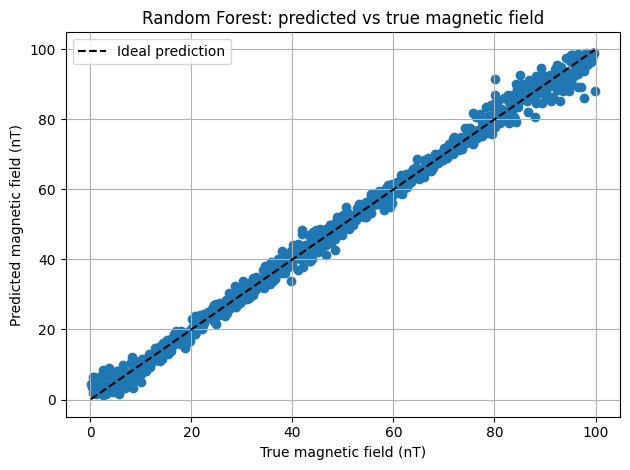

In [13]:
plt.scatter(y_test, y_pred)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "k--", label="Ideal prediction")
plt.xlabel("True magnetic field (nT)")
plt.ylabel("Predicted magnetic field (nT)")
plt.title("Random Forest: predicted vs true magnetic field")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The residual is the difference between the predicted and true magnetic field: ${r = B_{predicted}-B_{true}.}$

A residual distribution centred near zero indicates that the model does not have a large overall systematic offset.

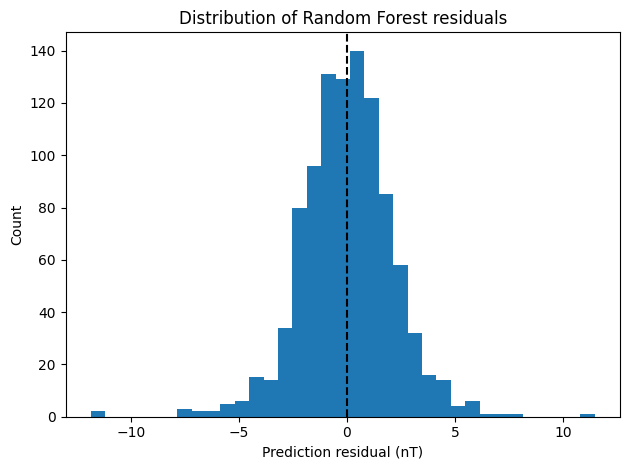

Mean residual:  0.028775297060713072  nT
Residual standard deviation:  2.1255577299067054  nT


In [14]:
residuals = y_pred - y_test.to_numpy()

plt.hist(residuals, bins=35)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Prediction residual (nT)")
plt.ylabel("Count")
plt.title("Distribution of Random Forest residuals")
plt.tight_layout()
plt.show()

print("Mean residual: ", np.mean(residuals), " nT")
print("Residual standard deviation: ", np.std(residuals), " nT")

Feature importance estimates how much each interrogation-time measurement contributes to the Random Forest predictions. It is a model-based measure, not proof that a particular interrogation time is universally optimal.

,Importance
P1_200us,0.760241
P1_400us,0.225289
P1_100us,0.012724
P1_50us,0.001132
P1_20us,0.000614


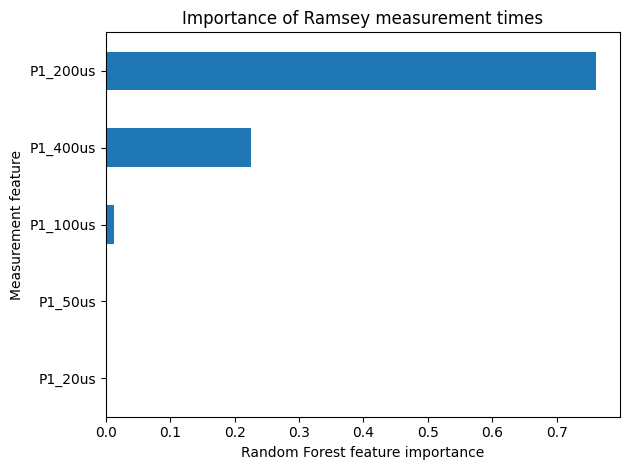

In [15]:
importance = pd.Series(rf_model.feature_importances_, index=feature_columns).sort_values(ascending=False)

display(importance.rename("Importance").to_frame())

importance.sort_values().plot(kind="barh")
plt.xlabel("Random Forest feature importance")
plt.ylabel("Measurement feature")
plt.title("Importance of Ramsey measurement times")
plt.tight_layout()
plt.show()